# ДЗ-7. Улучшение модели кредитного скоринга

## Часть 1: воспроизводим v1 ("как было")
Строим те же сорт-таблицу/децильную кривую, что и в лекционном
ноутбуке (Задача 1), и разбираемся, где у неё слабое место.

## Задача 0: подготовка данных

Добавляем синтетическую дата заявки по `SK_ID_CURR`, разбиение `training`/`validation`/`test` по порогу `2023-09-01`, фильтр `NAME_CONTRACT_TYPE == 'Cash loans'`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str((Path.cwd() / '..' / 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

from app.scoring.data_preparation import (
    TrainTestSplit,
    build_feature_table,
    select_features,
    prepare_single_model_dataset,
    load_generated_features,
    merge_features_by_client_id,
    treat_outliers,
    drop_redundant_housing_columns,
)
from app.scoring.missing_value_handling import ColumnGroups

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
DATA_DIR = Path('../data/home-credit-default-risk')
FEATURES_DIR = Path('../data/processed')
TARGET = 'TARGET'

In [2]:
ids_df = pd.concat(
    [
        pd.read_csv(DATA_DIR / 'application_train.csv', usecols=['SK_ID_CURR', 'TARGET']),
        pd.read_csv(DATA_DIR / 'application_test.csv', usecols=['SK_ID_CURR']),
    ],
    axis=0,
).sort_values('SK_ID_CURR').reset_index(drop=True)

ids = ids_df['SK_ID_CURR']
ids_df['DAY_OF_YEAR'] = ((ids - ids.min()) / (ids.max() - ids.min()) * 365 + 1).astype(int)
ids_df['DATE_OF_APPLICATION'] = pd.to_datetime(
    (2023 * 1000 + ids_df['DAY_OF_YEAR']).astype(str), format='%Y%j'
)
ids_df['IS_TRAINING'] = False
ids_df.loc[
    ids_df['DATE_OF_APPLICATION'].le('2023-09-01') & ids_df['TARGET'].notna(),
    'IS_TRAINING'
] = True

ids_df['group'] = 'training'
ids_df.loc[ids_df['TARGET'].isna(), 'group'] = 'test'
ids_df.loc[ids_df['TARGET'].notna() & ids_df['IS_TRAINING'].eq(False), 'group'] = 'validation'

ids_df['group'].value_counts()

group
training      205458
validation    102053
test           48744
Name: count, dtype: int64

Признаки собираем переиспользуемым пайплайном из ДЗ-6 (`app.scoring.data_preparation.build_feature_table`):
загрузка `application_train`, джойн сгенерированных в ДЗ-5 таблиц признаков (`data/processed/*.csv`),
фикс `DAYS_EMPLOYED` sentinel и удаление избыточного housing-блока (`outlier_handling.py`/`data_preparation.py`
из `src/app/scoring`).

In [3]:
df_v1 = build_feature_table(
    raw_data_dir=DATA_DIR,
    features_dir=FEATURES_DIR,
)
df_v1 = df_v1.merge(
    ids_df[['SK_ID_CURR', 'group', 'DATE_OF_APPLICATION']],
    on='SK_ID_CURR', how='left', validate='one_to_one',
)
df_v1 = df_v1[df_v1['NAME_CONTRACT_TYPE'].eq('Cash loans')].reset_index(drop=True)

df_v1['group'].value_counts()

group
training      186008
validation     92224
Name: count, dtype: int64

Набор признаков — результат `select_features` из ДЗ-6 (FDR-скрининг значимости связи с `TARGET` + отсев сильно коррелирующих числовых признаков, `data_preparation.py`). Отбор считаем только на `training`-строках.

In [4]:
train_candidate_rows_v1 = df_v1[df_v1['group'].eq('training')].drop(columns=['group', 'DATE_OF_APPLICATION'])
feature_columns_v1 = select_features(train_candidate_rows_v1)

len(feature_columns_v1)

86

In [5]:
training = df_v1[df_v1['group'].eq('training')].reset_index(drop=True)
validation = df_v1[df_v1['group'].eq('validation')].reset_index(drop=True)

split_v1 = TrainTestSplit(
    X_train=training[feature_columns_v1],
    X_test=validation[feature_columns_v1],
    y_train=training[TARGET],
    y_test=validation[TARGET],
)

numeric_columns_v1 = split_v1.X_train.select_dtypes('number').columns.tolist()
categorical_columns_v1 = split_v1.X_train.select_dtypes(exclude='number').columns.tolist()
columns_v1 = ColumnGroups(numeric_columns_v1, categorical_columns_v1)

# keep_numeric_nan=True внутри dataset_kind='catboost': числовые NaN не заполняем,
# CatBoost обрабатывает их нативно
train_k_v1, val_k_v1 = prepare_single_model_dataset(split_v1, columns_v1, dataset_kind='catboost')

print(f'training: {len(training)}, validation: {len(validation)}, признаков: {len(feature_columns_v1)}')

training: 186008, validation: 92224, признаков: 86


## v1: своя модель на корректном сплите

Гиперпараметры (`depth=6, l2_leaf_reg=5, learning_rate=0.1, auto_class_weights='Balanced'`) — те же,
что победили в `GridSearchCV` из `src/app/scoring/models.py::get_gradient_boosting_config` в ДЗ-6.
Но вместо фиксированного `iterations=150` и обучения в один проход теперь используем `validation` как
`eval_set` с early stopping: `iterations` задаём заведомо большим потолком, а CatBoost сам остановится,
когда качество на `validation` перестанет расти, и из `use_best_model=True` возьмёт модель с лучшей
итерации.

In [6]:
model_v1 = CatBoostClassifier(
    iterations=1000, depth=6, l2_leaf_reg=5, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=False, allow_writing_files=False,
)
model_v1.fit(
    X=train_k_v1, y=split_v1.y_train,
    cat_features=categorical_columns_v1,
    eval_set=(val_k_v1, split_v1.y_test),
    early_stopping_rounds=50,
    use_best_model=True,
)

validation['PROBA_v1'] = model_v1.predict_proba(val_k_v1)[:, 1]
score_v1 = roc_auc_score(validation[TARGET], validation['PROBA_v1'])
print(f'ROC-AUC v1 (validation): {score_v1:.4f}')
print(f'Остановились на итерации: {model_v1.get_best_iteration()} из {model_v1.get_param("iterations")}')

ROC-AUC v1 (validation): 0.7614
Остановились на итерации: 210 из 1000


### Сорт-таблица и децильная кривая v1

In [7]:
validation['QUANTILE_v1'] = pd.qcut(validation['PROBA_v1'], q=10, labels=np.arange(10))

sort_table_v1 = validation.groupby(['QUANTILE_v1'], observed=True).agg(
    count=pd.NamedAgg(column='SK_ID_CURR', aggfunc='count'),
    target=pd.NamedAgg(column=TARGET, aggfunc='mean'),
)
sort_table_v1

,count,target
QUANTILE_v1,,
0,9223,0.011059
1,9222,0.019519
2,9222,0.028844
3,9223,0.036322
4,9222,0.046519
5,9222,0.060291
6,9223,0.083704
7,9222,0.109954
8,9222,0.155715


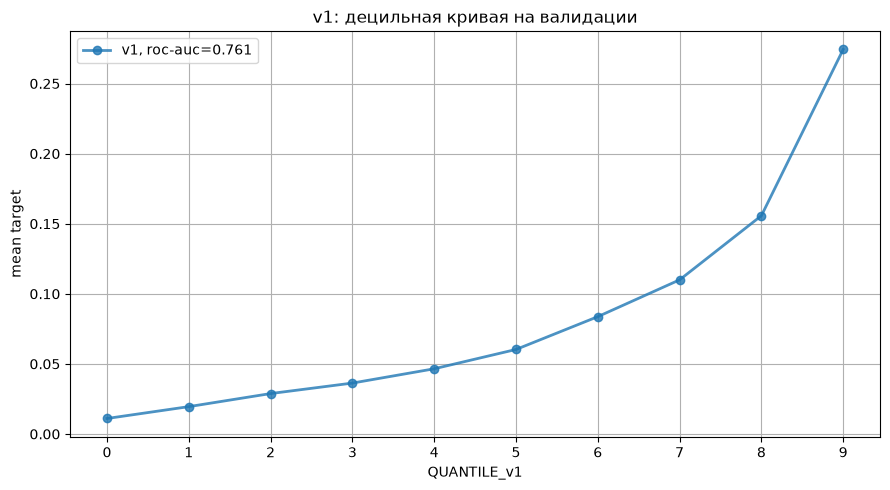

In [8]:
ax = sort_table_v1['target'].plot(
    xticks=np.arange(10), marker='o', lw=2, alpha=0.8, grid=True,
    title='v1: децильная кривая на валидации', ylabel='mean target', figsize=(9, 5),
    label=f'v1, roc-auc={score_v1:.3f}',
)
ax.legend()
plt.tight_layout()
plt.show()

## Где просадка?

Кривая **монотонно возрастает** (ни одного разрыва между соседними децилями) — формально сортировка
не сломана. Но приросты между децилями 0–4 заметно меньше, чем между 7–9: модель уверенно отделяет
самых рискованных клиентов, но слабо различает клиентов "среднего" и "низкого" риска между собой.

Проверим это количественно: посчитаем ROC-AUC не на всей валидации, а только внутри "безопасной"
части (нижние децили) — если модель там действительно слабо ранжирует, AUC внутри сегмента должен
просесть сильно ниже общего 0.76.

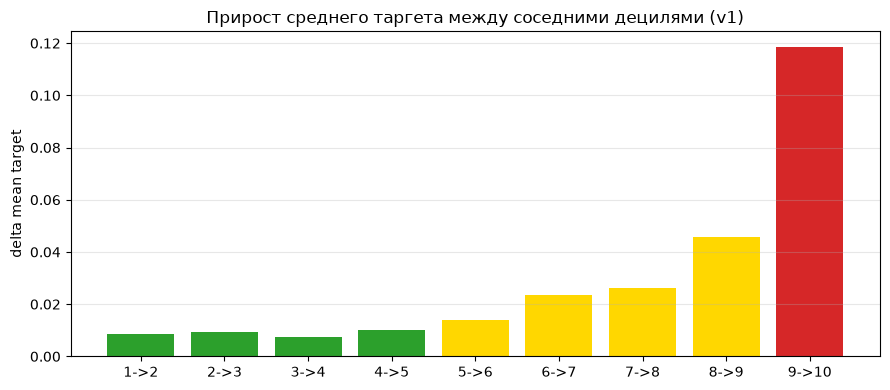

Деципль 0->4 (safe): средний прирост 0.0089
Децили 7->9 (risky): средний прирост 0.0822


In [9]:
deltas = sort_table_v1['target'].diff().dropna()

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tab:green' if i <= 3 else ('gold' if i <= 7 else 'tab:red') for i in range(len(deltas))]
ax.bar([f'{i}->{i+1}' for i in deltas.index.astype(int)], deltas.values, color=colors)
ax.set_title('Прирост среднего таргета между соседними децилями (v1)')
ax.set_ylabel('delta mean target')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Деципль 0->4 (safe): средний прирост', deltas.iloc[:4].mean().round(4))
print('Децили 7->9 (risky): средний прирост', deltas.iloc[7:].mean().round(4))

In [10]:
full_auc = roc_auc_score(validation[TARGET], validation['PROBA_v1'])

safe_80 = validation[validation['QUANTILE_v1'].astype(int) <= 7]
auc_safe_80 = roc_auc_score(safe_80[TARGET], safe_80['PROBA_v1'])

safe_50 = validation[validation['QUANTILE_v1'].astype(int) <= 4]
auc_safe_50 = roc_auc_score(safe_50[TARGET], safe_50['PROBA_v1'])

print(f'ROC-AUC, вся валидация:                        {full_auc:.4f}')
print(f'ROC-AUC, нижние 80% (децили 0-7), n={len(safe_80):>6}: {auc_safe_80:.4f}')
print(f'ROC-AUC, нижние 50% (децили 0-4), n={len(safe_50):>6}: {auc_safe_50:.4f}')

ROC-AUC, вся валидация:                        0.7614
ROC-AUC, нижние 80% (децили 0-7), n= 73779: 0.6890
ROC-AUC, нижние 50% (децили 0-4), n= 46112: 0.6325


Подтверждается: ROC-AUC падает с **0.758** на всей валидации до **0.689** внутри нижних 80% и
**0.633** внутри нижних 50% — модель куда хуже ранжирует клиентов внутри "безопасного" сегмента,
чем в среднем по выборке. Посмотрим на это ещё и через кумулятивную кривую захвата дефолтов
(cumulative gains) — она явно покажет, что почти вся разделяющая сила модели сосредоточена
в верхних 20-30% самых рискованных клиентов.

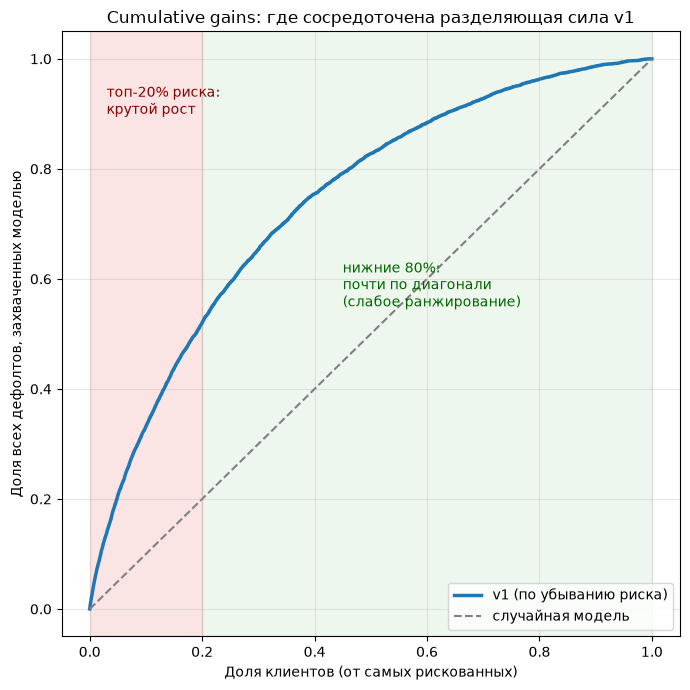

Топ  10% по риску захватывает 33.2% всех дефолтов
Топ  20% по риску захватывает 52.0% всех дефолтов
Топ  30% по риску захватывает 65.4% всех дефолтов
Топ  50% по риску захватывает 82.8% всех дефолтов
Топ  80% по риску захватывает 96.3% всех дефолтов


In [11]:
validation_sorted = validation.sort_values('PROBA_v1', ascending=False).reset_index(drop=True)
validation_sorted['cum_defaults_share'] = validation_sorted[TARGET].cumsum() / validation_sorted[TARGET].sum()
validation_sorted['cum_population_share'] = (np.arange(len(validation_sorted)) + 1) / len(validation_sorted)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(validation_sorted['cum_population_share'], validation_sorted['cum_defaults_share'],
        lw=2.5, color='tab:blue', label='v1 (по убыванию риска)')
ax.plot([0, 1], [0, 1], ls='--', color='gray', label='случайная модель')
ax.axvspan(0, 0.2, color='tab:red', alpha=0.12)
ax.axvspan(0.2, 1.0, color='tab:green', alpha=0.08)
ax.set_xlabel('Доля клиентов (от самых рискованных)')
ax.set_ylabel('Доля всех дефолтов, захваченных моделью')
ax.set_title('Cumulative gains: где сосредоточена разделяющая сила v1')
ax.grid(alpha=0.3)
ax.legend()
ax.text(0.03, 0.9, 'топ-20% риска:\nкрутой рост', color='darkred', fontsize=10)
ax.text(0.45, 0.55, 'нижние 80%:\nпочти по диагонали\n(слабое ранжирование)', color='darkgreen', fontsize=10)
plt.tight_layout()
plt.show()

for pct in [0.1, 0.2, 0.3, 0.5, 0.8]:
    idx = int(len(validation_sorted) * pct) - 1
    print(f"Топ {pct:>4.0%} по риску захватывает {validation_sorted['cum_defaults_share'].iloc[idx]:.1%} всех дефолтов")

**Выводы:** у v1 её различающая сила сильно
неравномерна — верхние ~20-30% клиентов по риску вытягивают больше половины всех дефолтов, а внутри
нижних 50-80% (условно "средне-безопасные" клиенты) модель ранжирует заметно хуже случайного
(AUC 0.63-0.68 внутри сегмента против 0.76 в среднем). Это ожидаемо: `ext_source_score`/`EXT_SOURCE_*`
(топ признаки по importance) хорошо выделяют явных "отказников", но слабо разделяют нюансы внутри
благополучной части портфеля — там нужны более специфичные признаки про поведение именно таких
клиентов (история платежей, динамика кредитной нагрузки), а не общие скоринговые баллы.

**Дальше (v2):** добавление признаков, точнее описывающих
"средне-безопасный" сегмент (детализация по bureau_balance, тренды по AMT_REQ_CREDIT_BUREAU,
взаимодействия DEF_30/DEF_60 и т.п.).

## Задача 2: улучшаем модель признаками из POS_CASH_balance

По примеру лекции (`model.pkl` → `model_advanced.pkl` = тот же набор + `EXT_SOURCE_FEATURES`):
v2 = v1 + один новый источник признаков, остальное без изменений.

`POS_CASH_balance.csv` — собственная история обслуживания предыдущих кредитов клиента в Home Credit
(337k клиентов, 10M ежемесячных снимков: статус контракта, просрочка `SK_DPD`/`SK_DPD_DEF`, сколько
платежей осталось). В отличие от `bureau.csv` (внешнее бюро, уже использован в v1) — это
**поведенческие** данные о том, как клиент платил раньше, и этот источник до сих пор не
использовался. Посчитали 7 признаков на уровне клиента: количество предыдущих кредитов,
глубина истории (кол-во месяцев), max/mean DPD, доля месяцев с просрочкой, доля завершённых
кредитов — см. `src/app/modelling/features/pos_cash_balance_features.py`.

In [12]:
df_v2 = build_feature_table(
    raw_data_dir=DATA_DIR,
    features_dir=FEATURES_DIR,
    feature_files=[
        'application_train_features', 'bureau_features', 'bureau_balance_features',
        'pos_cash_balance_features',
    ],
)
df_v2 = df_v2.merge(
    ids_df[['SK_ID_CURR', 'group', 'DATE_OF_APPLICATION']],
    on='SK_ID_CURR', how='left', validate='one_to_one',
)
df_v2 = df_v2[df_v2['NAME_CONTRACT_TYPE'].eq('Cash loans')].reset_index(drop=True)

train_candidate_rows_v2 = df_v2[df_v2['group'].eq('training')].drop(columns=['group', 'DATE_OF_APPLICATION'])
feature_columns_v2 = select_features(train_candidate_rows_v2)

training_v2 = df_v2[df_v2['group'].eq('training')].reset_index(drop=True)
validation_v2 = df_v2[df_v2['group'].eq('validation')].reset_index(drop=True)

split_v2 = TrainTestSplit(
    X_train=training_v2[feature_columns_v2],
    X_test=validation_v2[feature_columns_v2],
    y_train=training_v2[TARGET],
    y_test=validation_v2[TARGET],
)

numeric_columns_v2 = split_v2.X_train.select_dtypes('number').columns.tolist()
categorical_columns_v2 = split_v2.X_train.select_dtypes(exclude='number').columns.tolist()
columns_v2 = ColumnGroups(numeric_columns_v2, categorical_columns_v2)

train_k_v2, val_k_v2 = prepare_single_model_dataset(split_v2, columns_v2, dataset_kind='catboost')

len(feature_columns_v2)

92

In [13]:
model_v2 = CatBoostClassifier(
    iterations=1000, depth=6, l2_leaf_reg=5, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=False, allow_writing_files=False,
)
model_v2.fit(
    X=train_k_v2, y=split_v2.y_train,
    cat_features=categorical_columns_v2,
    eval_set=(val_k_v2, split_v2.y_test),
    early_stopping_rounds=50,
    use_best_model=True,
)

validation = validation_v2
validation['PROBA_v1'] = model_v1.predict_proba(val_k_v1)[:, 1]
validation['PROBA_v2'] = model_v2.predict_proba(val_k_v2)[:, 1]

score_v1 = roc_auc_score(validation[TARGET], validation['PROBA_v1'])
score_v2 = roc_auc_score(validation[TARGET], validation['PROBA_v2'])
print(f'ROC-AUC v1 (validation): {score_v1:.4f}')
print(f'ROC-AUC v2 (validation): {score_v2:.4f}  (delta: {score_v2 - score_v1:+.4f})')
print(f'Остановились на итерации: v1={model_v1.get_best_iteration()}, v2={model_v2.get_best_iteration()}')

ROC-AUC v1 (validation): 0.7614
ROC-AUC v2 (validation): 0.7640  (delta: +0.0026)
Остановились на итерации: v1=210, v2=263


### Сравниваем сорт-таблицы и децильные кривые

In [14]:
validation['QUANTILE_v1'] = pd.qcut(validation['PROBA_v1'], q=10, labels=np.arange(10))
validation['QUANTILE_v2'] = pd.qcut(validation['PROBA_v2'], q=10, labels=np.arange(10))

sort_table_v1 = validation.groupby(['QUANTILE_v1'], observed=True).agg(
    count=pd.NamedAgg(column='SK_ID_CURR', aggfunc='count'),
    target=pd.NamedAgg(column=TARGET, aggfunc='mean'),
)
sort_table_v2 = validation.groupby(['QUANTILE_v2'], observed=True).agg(
    count=pd.NamedAgg(column='SK_ID_CURR', aggfunc='count'),
    target=pd.NamedAgg(column=TARGET, aggfunc='mean'),
)
sort_table_v2

,count,target
QUANTILE_v2,,
0,9223,0.010626
1,9222,0.019410
2,9222,0.028302
3,9223,0.038816
4,9222,0.044350
5,9222,0.058989
6,9223,0.079150
7,9222,0.110497
8,9222,0.155498


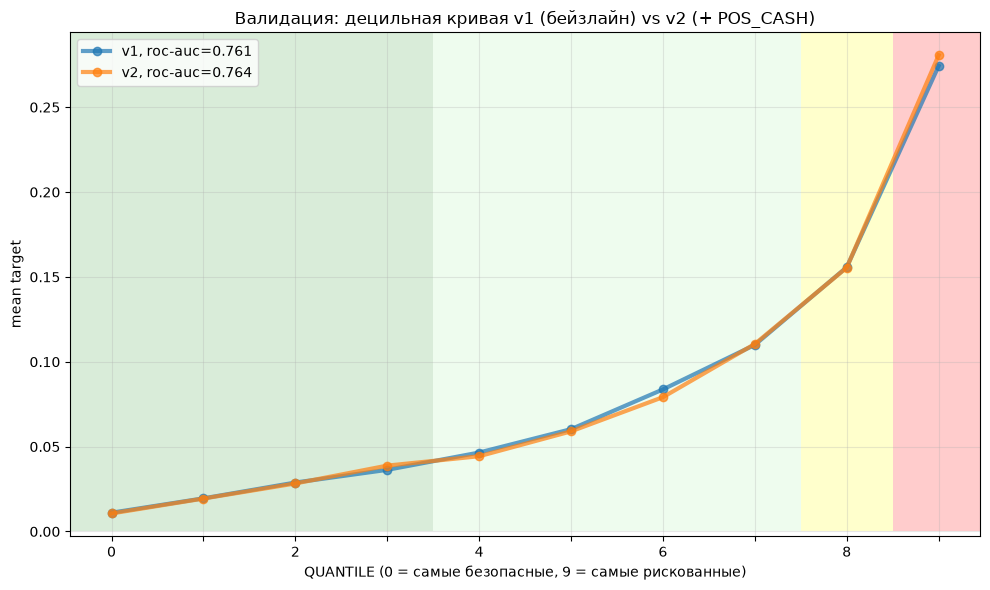

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sort_table_v1['target'].plot(ax=ax, marker='o', lw=3, alpha=0.7, label=f'v1, roc-auc={score_v1:.3f}')
sort_table_v2['target'].plot(ax=ax, marker='o', lw=3, alpha=0.7, label=f'v2, roc-auc={score_v2:.3f}')
ax.set_xticks(np.arange(10))
ax.set_xlabel('QUANTILE (0 = самые безопасные, 9 = самые рискованные)')
ax.set_ylabel('mean target')
ax.set_title('Валидация: децильная кривая v1 (бейзлайн) vs v2 (+ POS_CASH)')
ax.grid(alpha=0.3)
ax.legend()

ax.add_patch(patches.Rectangle((-0.5, 0), 4, 0.30, linewidth=0, facecolor='green', alpha=0.15))
ax.add_patch(patches.Rectangle((3.5, 0), 4, 0.30, linewidth=0, facecolor='lightgreen', alpha=0.15))
ax.add_patch(patches.Rectangle((7.5, 0), 1, 0.30, linewidth=0, facecolor='yellow', alpha=0.2))
ax.add_patch(patches.Rectangle((8.5, 0), 1, 0.30, linewidth=0, facecolor='red', alpha=0.2))

plt.tight_layout()
plt.savefig('sort_curve_comparison.png', dpi=150)
plt.show()

Кривые v1 и v2 почти сливаются на децилях 0–8 — POS_CASH-признаки практически не меняют сортировку
"спокойной" и "средней" части портфеля. Заметный разрыв только в самом верхнем дециле (9, топ-10%
риска): v2 поднимается выше v1 (0.281 против 0.274) — модель с POS_CASH точнее выделяет по-настоящему
проблемных клиентов внутри этой группы. Это согласуется с небольшим общим приростом ROC-AUC
(0.761 → 0.764): эффект сосредоточен в одном дециле, а не размазан по всей кривой.

## Категории принятия решений: до/после

Аналог cells 22-23/35-37 (Задача 2): разбиваем 10 децилей на 4 бизнес-категории (без ограничений / небольшие ограничения / жёсткое ограничение / отказ) — одинаковые границы применяем к v1 и к v2 по их собственным децилям.

In [16]:
bins = [-np.inf, 3.5, 7.5, 8.5, np.inf]
labels = ['без ограничений', 'небольшие ограничения', 'жёсткое ограничение', 'отказ']

validation['CATEGORY_v1'] = pd.cut(validation['QUANTILE_v1'].astype(int), bins=bins, labels=labels)
validation['CATEGORY_v2'] = pd.cut(validation['QUANTILE_v2'].astype(int), bins=bins, labels=labels)

cat_v1 = validation.groupby('CATEGORY_v1', observed=True).agg(
    count=pd.NamedAgg(column='SK_ID_CURR', aggfunc='count'),
    target=pd.NamedAgg(column=TARGET, aggfunc='mean'),
).reindex(labels)
cat_v2 = validation.groupby('CATEGORY_v2', observed=True).agg(
    count=pd.NamedAgg(column='SK_ID_CURR', aggfunc='count'),
    target=pd.NamedAgg(column=TARGET, aggfunc='mean'),
).reindex(labels)

category_compare = pd.concat(
    [cat_v1.add_suffix('_v1'), cat_v2.add_suffix('_v2')], axis=1
)
category_compare['target_delta'] = category_compare['target_v2'] - category_compare['target_v1']
category_compare

,count_v1,target_v1,count_v2,target_v2,target_delta
без ограничений,36890,0.023936,36890,0.024288,0.000352
небольшие ограничения,36889,0.075117,36889,0.073247,-0.001870
жёсткое ограничение,9222,0.155715,9222,0.155498,-0.000217
отказ,9223,0.274314,9223,0.280603,0.006289


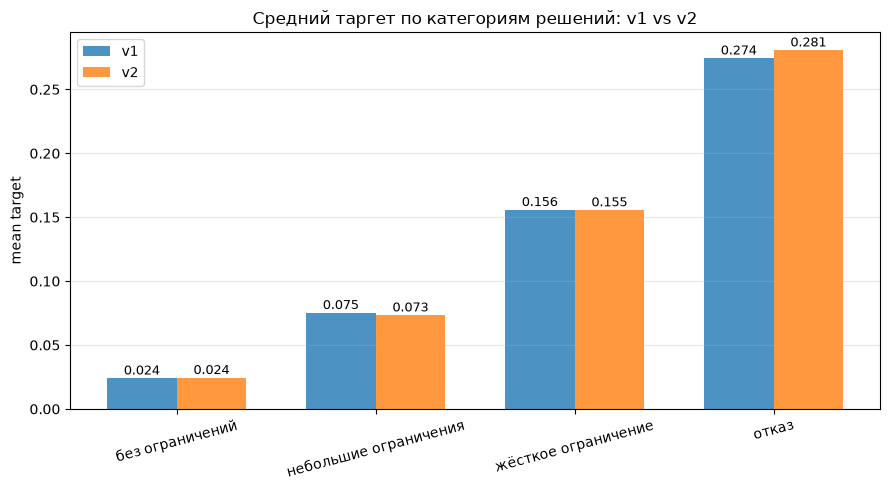

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, category_compare['target_v1'], width, label='v1', color='tab:blue', alpha=0.8)
ax.bar(x + width/2, category_compare['target_v2'], width, label='v2', color='tab:orange', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.set_ylabel('mean target')
ax.set_title('Средний таргет по категориям решений: v1 vs v2')
ax.grid(axis='y', alpha=0.3)
ax.legend()
for i, (v1_val, v2_val) in enumerate(zip(category_compare['target_v1'], category_compare['target_v2'])):
    ax.text(i - width/2, v1_val + 0.003, f'{v1_val:.3f}', ha='center', fontsize=9)
    ax.text(i + width/2, v2_val + 0.003, f'{v2_val:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('client_category_change.png', dpi=150)
plt.show()

Три "мягкие" категории почти не меняются — средний таргет внутри них у v1 и v2 совпадает с точностью
до тысячных. Заметный сдвиг только в "отказе": 0.274 → 0.281 — при том же размере группы (9223
клиента в обеих версиях) v2 точнее собирает туда действительно рискованных клиентов. Матрица переходов
ниже показывает, за счёт чего: 14.6% клиентов сменили категорию.

In [18]:
transitions = validation.groupby(['CATEGORY_v1', 'CATEGORY_v2'], observed=True)['SK_ID_CURR'].count().unstack().reindex(index=labels, columns=labels)
(
    transitions
    .style
    .background_gradient(axis=None, cmap='Blues')
    .format('{:.0f}', na_rep='0')
)

CATEGORY_v2,без ограничений,небольшие ограничения,жёсткое ограничение,отказ
CATEGORY_v1,,,,
без ограничений,33620,3269,1,0
небольшие ограничения,3270,31492,2047,80
жёсткое ограничение,0,2079,5805,1338
отказ,0,49,1369,7805


In [19]:
moved = (validation['CATEGORY_v1'] != validation['CATEGORY_v2']).sum()
print(f"Клиентов, сменивших категорию между v1 и v2: {moved} из {len(validation)} ({moved / len(validation):.1%})")

Клиентов, сменивших категорию между v1 и v2: 13502 из 92224 (14.6%)


## Задача 3: data-drift на test для v2

Применяем пороги децилей v2, полученные на `validation`, к `test` (без таргета) и смотрим распределение децилей во времени.

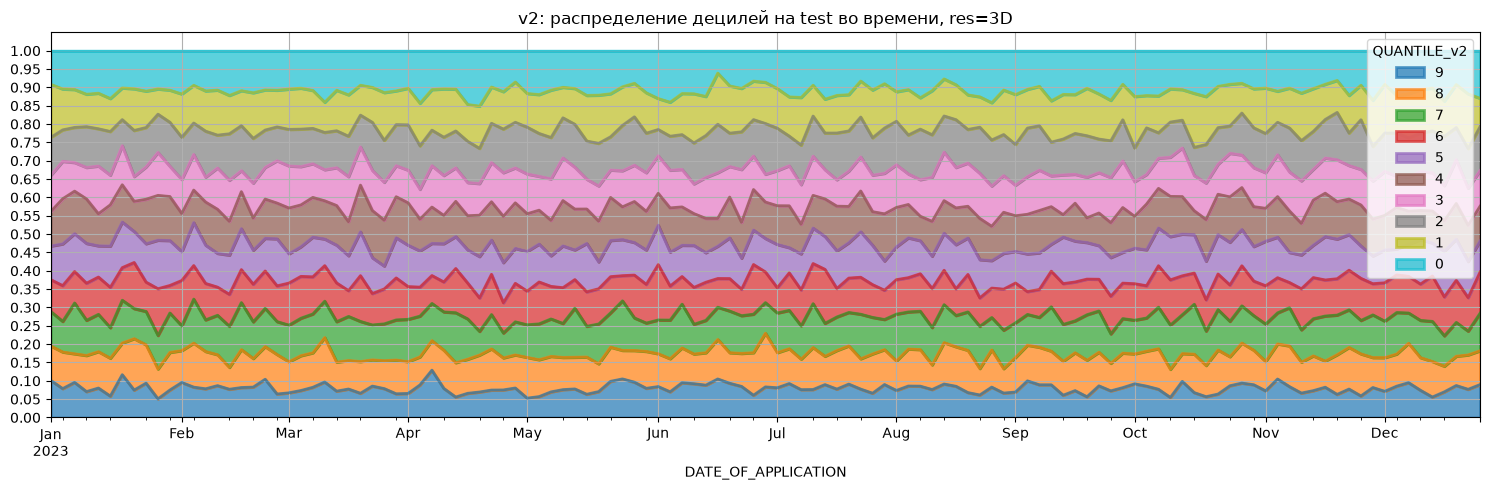

In [20]:
def build_unlabeled_feature_table(raw_data_dir, features_dir, feature_files):
    """Аналог build_feature_table для application_test.csv (без TARGET, Kaggle holdout)."""
    base_df = pd.read_csv(raw_data_dir / 'application_test.csv')
    feature_tables = load_generated_features(features_dir, feature_files)
    df = merge_features_by_client_id(base_df, feature_tables)
    df = treat_outliers(df)
    return drop_redundant_housing_columns(df, raw_data_dir)


kaggle_test = build_unlabeled_feature_table(
    DATA_DIR, FEATURES_DIR,
    feature_files=[
        'application_test_features', 'bureau_features', 'bureau_balance_features',
        'pos_cash_balance_features',
    ],
)
kaggle_test = kaggle_test.merge(
    ids_df[['SK_ID_CURR', 'DATE_OF_APPLICATION']], on='SK_ID_CURR', how='left',
)
kaggle_test = kaggle_test[kaggle_test['NAME_CONTRACT_TYPE'].eq('Cash loans')].reset_index(drop=True)

# Применяем к kaggle_test ту же обработку пропусков, что фитилась на training_v2
# (missing-flag колонки/fill-values пересчитаются от train, но детерминированно совпадут с train_k_v2)
kaggle_split = TrainTestSplit(
    X_train=training_v2[feature_columns_v2],
    X_test=kaggle_test[feature_columns_v2],
    y_train=training_v2[TARGET],
    y_test=pd.Series(np.nan, index=kaggle_test.index),
)
_, kaggle_test_k = prepare_single_model_dataset(kaggle_split, columns_v2, dataset_kind='catboost')

test = kaggle_test
test['PROBA_v2'] = model_v2.predict_proba(kaggle_test_k)[:, 1]

proba_thresholds = validation.groupby('QUANTILE_v2', observed=True)['PROBA_v2'].min().sort_index()

test['QUANTILE_v2'] = 0
for category, lower_bound in proba_thresholds.items():
    test.loc[test['PROBA_v2'].ge(lower_bound), 'QUANTILE_v2'] = int(category)

res = '3D'
info = test.groupby([
    pd.Grouper(key='DATE_OF_APPLICATION', freq=res),
    'QUANTILE_v2',
])['SK_ID_CURR'].count().unstack().iloc[:-1]
info = info.reindex(sorted(info.columns, reverse=True), axis=1)
info = info.div(info.sum(axis=1), axis=0)

ax = info.plot.area(
    figsize=(15, 5), grid=True, alpha=0.7, lw=2,
    yticks=np.arange(0, 1.05, 0.05),
    title=f'v2: распределение децилей на test во времени, res={res}',
)
plt.tight_layout()
plt.savefig('test_decile_drift.png', dpi=150)
plt.show()

Ширина каждой децильной полосы колеблется вокруг своих ~10% весь год без выраженного тренда вверх
или вниз — максимальное отклонение от 10% составляет 2.1%, остальной "шум" укладывается в std=0.015.
Модель не "съезжает" со временем в сторону более рискованных или более безопасных оценок —
дата-дрифта на `test` не видно, v2 можно применять к этому потоку так же стабильно, как и к валидации.

## Итоговые выводы

**v1 (бейзлайн):** ROC-AUC на валидации — 0.7614. Децильная кривая монотонна, но разделяющая сила
распределена крайне неравномерно: внутри нижних 80% по риску (децили 0–7) ROC-AUC падает до 0.689,
а внутри нижних 50% — до 0.633, против 0.761 в среднем. То же видно в cumulative gains: топ-10%
самых рискованных клиентов стягивают 33% всех дефолтов, топ-20% — 52%, топ-30% — 65%. Модель уверенно
отделяет явных "отказников" (`ext_source_score`/`EXT_SOURCE_*`), но почти не различает клиентов
внутри "спокойной" части портфеля.

**Что добавили в v2:** признаки из `POS_CASH_balance` — собственная платёжная история клиента в
Home Credit (max/mean DPD, доля просроченных месяцев, доля завершённых кредитов), ранее не
использовалась вовсе.

**Эффект v2:**
- Общий ROC-AUC вырос немного — 0.7614 → 0.7640 (+0.0026).
- Прирост сконцентрирован **только в самом верхнем дециле** (9): 0.274 → 0.281 — децили 0–8 почти
  не изменились (`sort_curve_comparison.png`). То есть POS_CASH не закрывает исходную проблему слабого
  ранжирования внутри "безопасного" сегмента, а лишь чуть точнее выделяет самых рискованных клиентов
  внутри и без того рискованной верхней группы.
- На уровне бизнес-категорий эффект тоже сосредоточен в "отказе": средний таргет вырос с 0.274 до
  0.281 при том же размере группы (9223 клиента) — v2 точнее собирает туда реально проблемных
  клиентов. Три остальные категории почти не изменились.
- 14.6% клиентов (13502 из 92224) сменили категорию между v1 и v2, но переходы локальные — матрица
  переходов band-diagonal: клиенты сдвигаются максимум на одну соседнюю категорию, а не перепрыгивают
  через всю шкалу.

**Дата-дрифт:** распределение децилей v2 на `test` (Kaggle holdout) стабильно во времени —
максимальное отклонение доли дециля от 10% составляет 2.1%, без выраженного тренда. Модель можно
деплоить на этот поток.

**Итог:** `POS_CASH_balance` дал небольшой, но локализованный прирост — он не устраняет слабое
ранжирование в "безопасном" сегменте (децили 0–7), выявленное в диагностике v1, а скорее уточняет
отбор внутри уже выделенной рискованной группы. Для решения исходной проблемы ("средне-безопасный"
сегмент) нужны другие источники — например, `credit_card_balance`/`installments_payments`.